##### 2-1. 합성데이터 생성
<pre style="font-size:16px">
# colab -> Colab CPU -> terminal
wget https://raw.githubusercontent.com/code-archive-git/ai/refs/heads/main/production/data/stop_events.csv
</pre>

##### 2-2. [1단계] 클래스 불균형 확인

loss_type
설비    0.607
자재    0.208
품질    0.128
운영    0.057
Name: proportion, dtype: float64


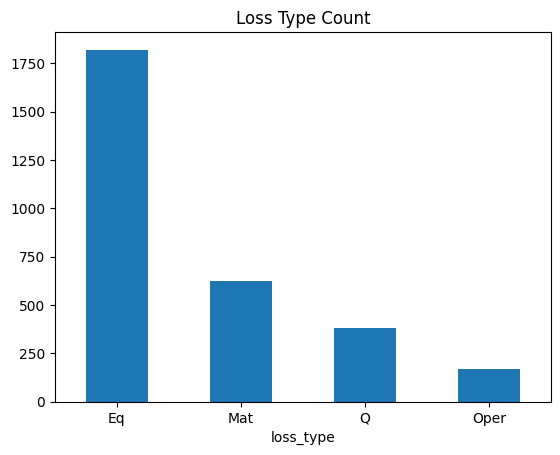

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/content/data/stop_events.csv')
# loss_type 을 세는데, 비율로써 계산해줘, 그리고 소숫점 3자리로 표현
print(df['loss_type'].value_counts(normalize=True).round(3))
df['loss_type'].value_counts().plot.bar(title='Loss Type Count')
plt.xticks(ticks=[0,1,2,3],labels=['Eq', 'Mat', 'Q', 'Oper'], rotation=0)
plt.show()

In [29]:
# df.drop(columns=['loss_type', 'duration']) : 정답인 loss_type, 그리고 정답을 추론할수 있는 duration 제거.
# pd.get_dummies() : 문자열 데이터를 숫자(0과 1) 형태의 데이터로 변환(원-핫 인코딩, One-Hot Encoding)
# columns=['shift']: shift 컬럼을 대상으로
# dtype=int: True/False -> 0|1(정수형)으로 
X = pd.get_dummies(df.drop(columns=['loss_type', 'duration']), columns=['shift'], dtype=int)
y = df['loss_type']
# 만들고 나서 X 를 확인해 보면 shift_야간,shift_주간 으로 변경되어 있음을 알 수 있다.
X.head()

,alarm_cnt,equip_temp,prev_ct,material_in,wip_buffer,ng_cnt,shift_야간,shift_주간
0,1,65.391425,41.672671,1,4,1,0,1
1,2,67.343397,46.115500,0,8,3,0,1
2,7,68.489734,49.394085,1,10,1,0,1
3,6,72.852641,49.816136,1,8,1,0,1
4,0,58.639210,46.221190,0,5,3,0,1


##### 2-3. [2단계] SMOTE 등 리샘플링

In [ ]:
!pip install imbalanced-learn
from collections import Counter
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
import pandas as pd

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)

In [ ]:
# SMOTE 를 쓰려면 이렇게 끝내면 됨
x_res, y_res = SMOTE(random_state=0).fit_resample(x_train, y_train)
print('before :', Counter(y_train))
print('after  :', Counter(y_res))

before : Counter({'설비': 1275, '자재': 437, '품질': 268, '운영': 120})
after  : Counter({'설비': 1275, '자재': 1275, '품질': 1275, '운영': 1275})


In [32]:
#SMOTENC
from imblearn.over_sampling import SMOTENC

# X 데이터에서 범주형/이진형 변수들의 컬럼 인덱스(위치 번호) 찾기
# 아래 코드는 열 이름으로 범주형 컬럼 위치를 자동으로 찾아줍니다.
categorical_features_idx = [] 
for col in ['material_in', 'shift_주간', 'shift_야간']: # 해당 컬럼명을
    if col in X.columns: # X 컬럼들 중에 있는지 찾아서
        # print(f'{col} : {X.columns.get_loc(col)}')
        categorical_features_idx.append(X.columns.get_loc(col)) # 컬럼인덱스를 넣는다.
print(categorical_features_idx)

[3, 7, 6]


In [33]:
# SMOTENC 적용
smote_nc = SMOTENC(categorical_features=categorical_features_idx, random_state=0)
x_res, y_res = smote_nc.fit_resample(x_train, y_train)

print('before :', Counter(y_train))
print('after  :', Counter(y_res))

before : Counter({'설비': 1275, '자재': 437, '품질': 268, '운영': 120})
after  : Counter({'설비': 1275, '자재': 1275, '품질': 1275, '운영': 1275})


##### 2-4. [3단계] 분류모델 학습

In [36]:
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [37]:
candidates = {}
# LogisticRegression
candidates['LR (기본)'] = Pipeline([('sc', StandardScaler()),('m', LogisticRegression(max_iter=2000))])
candidates['LR (weight)'] = Pipeline([
    ('sc', StandardScaler()),
    ('m', LogisticRegression(max_iter=2000, class_weight='balanced'))
])
candidates['LR (SMOTENC)'] = Pipeline([
    ('sc', StandardScaler()),
    ('smote', SMOTENC(categorical_features=categorical_features_idx, random_state=0)),
    ('m', LogisticRegression(max_iter=2000))
])

In [38]:
# RandomForestClassifier
candidates['RF (기본)'] = Pipeline([('m', RandomForestClassifier(n_estimators=300, random_state=0))])
candidates['RF (weight)'] = Pipeline([
    ('m', RandomForestClassifier(n_estimators=300, random_state=0, class_weight='balanced'))
])
candidates['RF (SMOTENC)'] = Pipeline([
    ('smote', SMOTENC(categorical_features=categorical_features_idx, random_state=0)),
    ('m', RandomForestClassifier(n_estimators=300, random_state=0))
])

In [39]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
# f1 : 정밀도(Precision)와 재현율(Recall)의 조화평균
# f1_macro(단순 평균): 모든 클래스의 F1-score를 각각 구한 뒤 똑같이 1/n로 단순 평균을 냄
# f1_weighted(가중 평균): 데이터 개수가 많은 클래스에 더 큰 가중치를 주어 평균을 냄
for name, model in candidates.items():
    s = cross_val_score(model, x_train, y_train, cv=cv, scoring='f1_macro')
    print(f'{name:12s} macro-F1 = {s.mean():.3f} ± {s.std():.3f}')

LR (기본)      macro-F1 = 0.851 ± 0.026
LR (weight)  macro-F1 = 0.817 ± 0.026
LR (SMOTENC) macro-F1 = 0.827 ± 0.027
RF (기본)      macro-F1 = 0.829 ± 0.031
RF (weight)  macro-F1 = 0.830 ± 0.026
RF (SMOTENC) macro-F1 = 0.822 ± 0.027


##### 2-5. [4단계] macro-F1 평가 · 혼동행렬

In [40]:
# 1 등으로 해야 하지만 그냥 이걸로 해 보자
best = candidates['RF (SMOTENC)'].fit(x_train, y_train)
pred = best.predict(x_test)

In [41]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score
# macro-F1 평가
f1_score = f1_score(y_test, pred, average='macro') # 정답과 예측값을 대조헤서 macro 방식으로 F1 추출
print(f'macro-F1 : {f1_score:.3f}')
# 각 부서/유형별로 얼마나 잘 맞히고 있는지 상세 성적표
detail_score = classification_report(y_test, pred, digits=3) # digits=3 <- 소숫점 세자리
print(detail_score) # support : 정답데이터의 수

macro-F1 : 0.797
              precision    recall  f1-score   support

          설비      0.943     0.945     0.944       546
          운영      0.452     0.549     0.496        51
          자재      0.983     0.904     0.942       188
          품질      0.797     0.817     0.807       115

    accuracy                          0.898       900
   macro avg      0.794     0.804     0.797       900
weighted avg      0.905     0.898     0.901       900



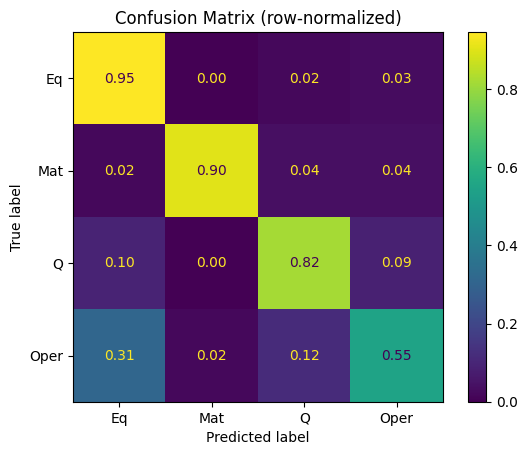

In [42]:
# 혼동행렬
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=['설비', '자재', '품질', '운영'],
                                        normalize='true', values_format='.2f')
plt.title('Confusion Matrix (row-normalized)')
plt.xticks(ticks=[0,1,2,3],labels=['Eq', 'Mat', 'Q', 'Oper'], rotation=0)
plt.yticks(ticks=[0,1,2,3],labels=['Eq', 'Mat', 'Q', 'Oper'], rotation=0)
plt.show()

##### 2-6. [5단계] 로스 Top 원인 리포트

In [43]:
# 원본에서 duration 부분 복사해서 가져옴
report = df.loc[x_test.index, ['duration']].copy()
# 예측한 타입도 넣어준다.
report['pred_type'] = pred
report.head()

,duration,pred_type
2518,2.1,운영
1072,24.4,자재
560,23.8,자재
2701,3.7,설비
851,25.0,자재


In [49]:
# 유형별로 묶어서 duration 을 count, sum, mean 연산을 해라
grouped = report.groupby('pred_type')['duration'].agg(['count', 'sum', 'mean'])
grouped

,count,sum,mean
pred_type,,,
설비,547,15798.1,28.881353
운영,62,1247.5,20.120968
자재,173,3810.9,22.028324
품질,118,1853.1,15.704237


In [48]:
# 한글 컬럼명으로 바꾸고 정지시간이 큰 유형부터 내림차순으로 정렬
# 예쁘게 엔터를 넣어주기 위한 괄호
summary = (grouped
           .rename(columns={'count': '건수', 'sum': '총정지(분)', 'mean': '평균정지(분)'})
           .sort_values('총정지(분)', ascending=False))
summary


,건수,총정지(분),평균정지(분)
pred_type,,,
설비,547,15798.1,28.881353
자재,173,3810.9,22.028324
품질,118,1853.1,15.704237
운영,62,1247.5,20.120968


<pre style="font-size: 18px">
아래에서 하고자 하는 내용
1번(설비): 600
2번(설비 + 자재): 600 + 200 = 800
3번(설비 + 자재 + 품질): 800 + 150 = 950
4번(설비 + 자재 + 품질 + 운영): 950 + 50 = 1000 (전체 합계)
위 내용을 누적비율로 계산하면...
설비 누적 비율: 600 / 1000 = 0.6 (60%)
자재 누적 비율: 800 / 1000 = 0.8 (80%)
품질 누적 비율: 950 / 1000 = 0.95 (95%)
운영 누적 비율: 1000 / 1000 = 1.0 (100%)
</pre>

In [ ]:
# 누적 비율 컬럼을 추가 = 누적 총 정지 시간 / 총 정지 시간 * 100
summary['누적비율(%)'] = (summary['총정지(분)'].cumsum() / summary['총정지(분)'].sum() * 100).round(1)
# 설비 + 자재 = 86% 의 누적비율이 나왔다.
summary

,건수,총정지(분),평균정지(분),누적비율(%)
pred_type,,,,
설비,547,15798.1,28.881353,69.6
자재,173,3810.9,22.028324,86.3
품질,118,1853.1,15.704237,94.5
운영,62,1247.5,20.120968,100.0


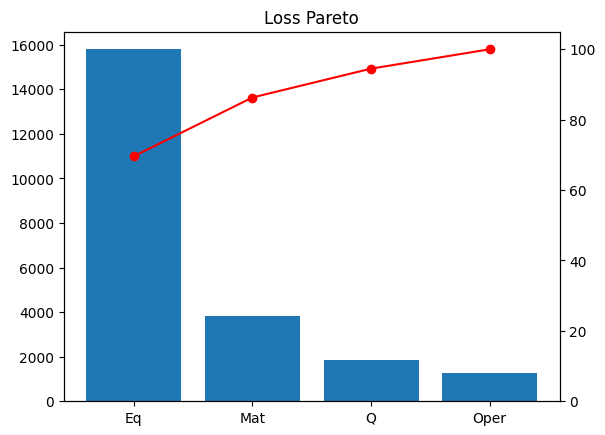

In [53]:
# 파레토 차트(총 정지 분을 막대 그래프로, 누적비율을 라인그래프로 그린다.)
fig, ax = plt.subplots()
ax.bar(summary.index, summary['총정지(분)'])
ax2 = ax.twinx()
ax2.plot(summary.index, summary['누적비율(%)'], 'r-o')
ax2.set_ylim(0, 105)
plt.title('Loss Pareto')
plt.xticks(ticks=[0,1,2,3],labels=['Eq', 'Mat', 'Q', 'Oper'], rotation=0)
plt.show()

In [54]:
# 분류 근거 : 특징 중요도
rf = best.named_steps['m']
pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

,0
ng_cnt,0.260378
alarm_cnt,0.176903
wip_buffer,0.173211
material_in,0.168847
equip_temp,0.133817
prev_ct,0.077486
shift_주간,0.004894
shift_야간,0.004464
